# Ипорты

In [1]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import date, timedelta
from typing import Optional

from sklearn.metrics import mean_squared_error
from catboost import CatBoostRegressor

# База по данным

In [2]:
data = pl.read_parquet('data/train.parquet')
data.shape

(30631006, 18)

In [3]:
data.columns

['event_date',
 'user_id',
 'search',
 'cat',
 'has_search_to_cart',
 'has_search_to_ord',
 'has_cat_to_cart',
 'has_cat_to_ord',
 'search_to_cart',
 'search_to_ord',
 'cat_to_cart',
 'cat_to_ord',
 'gmv_search',
 'gmv_cat',
 'to_cart',
 'to_ord',
 'gmv',
 'searches']

In [4]:
display(data.dtypes)
display(data.null_count())

[Date,
 Int64,
 Int64,
 Int64,
 Int64,
 Int64,
 Int64,
 Int64,
 Int64,
 Int64,
 Int64,
 Int64,
 Float64,
 Float64,
 Int64,
 Int64,
 Float64,
 Int64]

event_date,user_id,search,cat,has_search_to_cart,has_search_to_ord,has_cat_to_cart,has_cat_to_ord,search_to_cart,search_to_ord,cat_to_cart,cat_to_ord,gmv_search,gmv_cat,to_cart,to_ord,gmv,searches
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [5]:
data.head()

event_date,user_id,search,cat,has_search_to_cart,has_search_to_ord,has_cat_to_cart,has_cat_to_ord,search_to_cart,search_to_ord,cat_to_cart,cat_to_ord,gmv_search,gmv_cat,to_cart,to_ord,gmv,searches
date,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,i64,i64,f64,i64
2025-06-16,2,1,0,0,0,0,0,0,0,0,0,0.0,0.0,0,0,0.0,2
2025-06-22,2,1,0,1,0,0,0,1,0,0,0,0.0,0.0,1,0,0.0,1
2025-08-08,2,1,0,0,0,0,0,0,0,0,0,0.0,0.0,0,0,0.0,1
2025-08-18,2,1,0,1,0,0,0,1,0,0,0,0.0,0.0,1,0,0.0,1
2025-08-23,2,1,0,0,0,0,0,0,0,0,0,0.0,0.0,0,0,0.0,1


# По user_id

In [6]:
data['user_id'].n_unique()

250000

In [7]:
user_days = (data.group_by('user_id').len().sort('len', descending=True))

user_days.head(20)

user_id,len
i64,u32
266754,409
395678,409
272862,409
704679,409
689793,408
…,…
763777,407
658590,407
863588,407


In [8]:
user_days['len'].describe()

statistic,value
str,f64
"""count""",250000.0
"""null_count""",0.0
"""mean""",122.524024
"""std""",87.445046
"""min""",3.0
"""25%""",51.0
"""50%""",102.0
"""75%""",178.0
"""max""",409.0


In [9]:
data.group_by('user_id').len()  # Дней активности у каждого пользователя

user_id,len
i64,u32
180629,66
205144,31
688057,29
759485,187
736551,93
…,…
279704,17
537555,175
674918,67


In [10]:
display((data.group_by('user_id').len()).sort(by='len', descending=True).head(10))
display((data.group_by('user_id').len()).sort(by='len').head(10))

user_id,len
i64,u32
266754,409
395678,409
272862,409
704679,409
689793,408
50957,408
258346,408
48543,408
75443,408


user_id,len
i64,u32
593683,3
328496,3
862910,3
823199,3
856092,3
820308,3
242774,3
237522,3
519221,3


Количество человек с максимальной и минимальной актиностью

In [11]:
display(((data.group_by('user_id').len()).sort(by='len', descending=True))['len'].value_counts().head(10))
display(((data.group_by('user_id').len()).sort(by='len'))['len'].value_counts().head(10))


len,count
u32,u32
409,4
408,8
407,8
406,10
405,5
404,7
403,23
402,8
401,7


len,count
u32,u32
3,156
4,239
5,444
6,577
7,653
8,762
9,860
10,936
11,1045


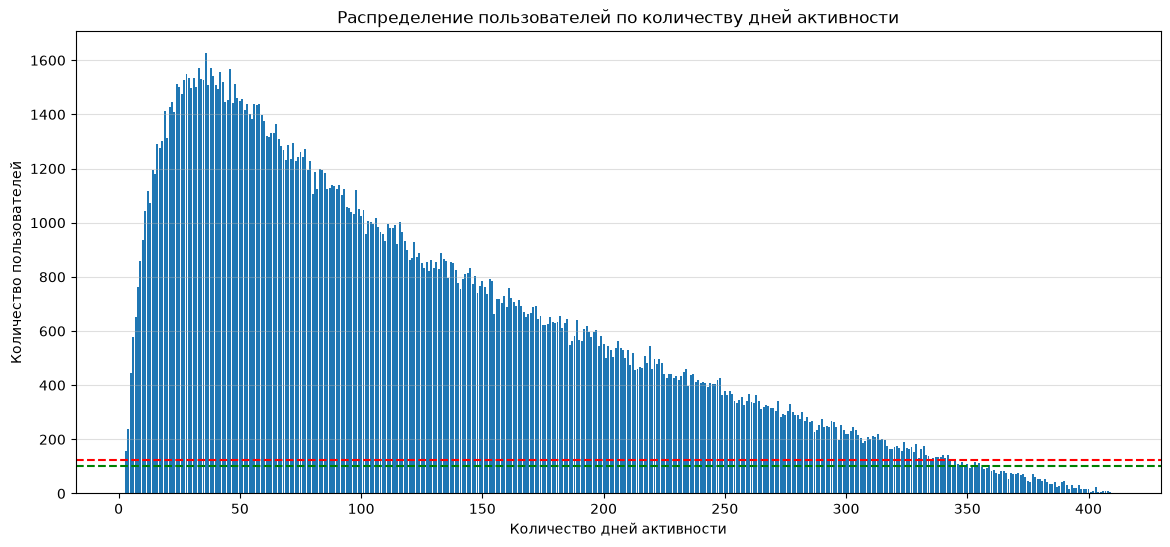

Среднее количество дней активности на одного пользователя: 122.52
Медиана: 102.00


In [12]:
x = ((data.group_by('user_id').len()).sort(by='len'))['len'].value_counts()['len'].to_numpy()
y = ((data.group_by('user_id').len()).sort(by='len'))['len'].value_counts()['count'].to_numpy()

median_value = np.median(np.repeat(x, y)) # repeat оказывается важнее, так как я же сгруппировал по userr_id
mean_value = np.mean(np.repeat(x, y))

fig, ax = plt.subplots(figsize=(14, 6))

ax.bar(x, y)

ax.set_title('Распределение пользователей по количеству дней активности')
ax.set_xlabel('Количество дней активности')
ax.set_ylabel('Количество пользователей')
ax.grid(axis='y', alpha=0.4)

ax.axhline(median_value, 0, max(y), color='green', linestyle='--', label=f'Медиана: {median_value}')
ax.axhline(mean_value, 0, max(y), color='red', linestyle='--', label=f'Среднее: {mean_value}')

plt.show()

print(f'Среднее количество дней активности на одного пользователя: {mean_value:.2f}')
print(f'Медиана: {median_value:.2f}') # крч, 50% пользователей имеют актиность меньше это числа, а другие 50% болььше

# Даты

In [15]:
display(data['event_date'].min())
display(data['event_date'].max())

datetime.date(2025, 1, 1)

datetime.date(2026, 2, 13)

Сколько строк в каждый день

In [ ]:
daily = (
    data
    .group_by('event_date')
    .len()
    .sort('event_date')
)

daily.head(10)

event_date,len
date,u32
2025-01-01,43516
2025-01-02,52556
2025-01-03,53609
2025-01-04,54882
2025-01-05,55531
2025-01-06,54063
2025-01-07,55408
2025-01-08,59303
2025-01-09,58872


In [17]:
daily.describe()

statistic,event_date,len
str,str,f64
"""count""","""409""",409.0
"""null_count""","""0""",0.0
"""mean""","""2025-07-24 00:00:00""",74892.435208
"""std""",null,13156.051234
"""min""","""2025-01-01""",43516.0
"""25%""","""2025-04-13""",64544.0
"""50%""","""2025-07-24""",69960.0
"""75%""","""2025-11-03""",86805.0
"""max""","""2026-02-13""",103617.0


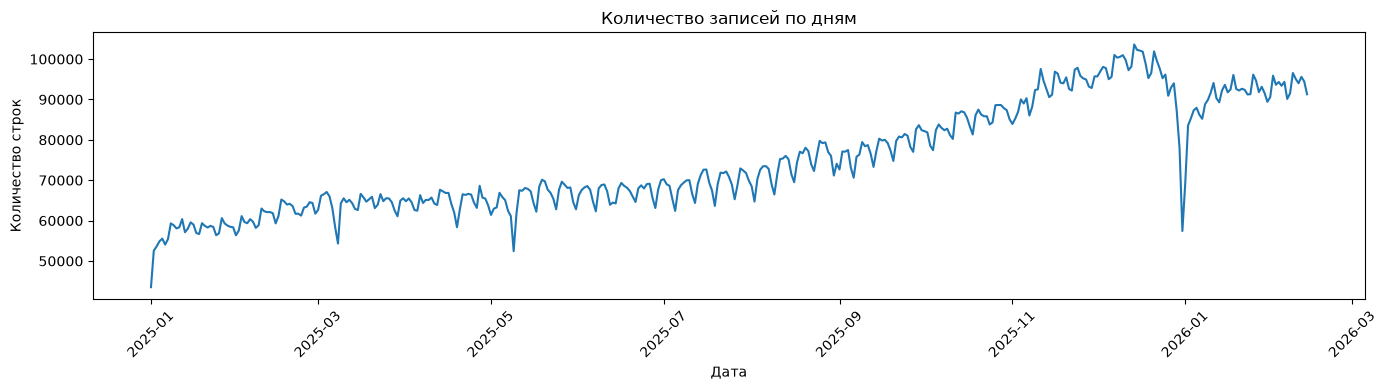

In [19]:
plt.figure(figsize=(14, 4))

plt.plot(
    daily['event_date'],
    daily['len']
)

plt.title('Количество записей по дням')
plt.xlabel('Дата')
plt.ylabel('Количество строк')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()